<a href="https://colab.research.google.com/github/guizyre/metodos_numericos/blob/main/Gradiente_Descendente.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import numpy as np

def f1(x): return 2*x**4 + 4*x**3 + 3*x**2 - 10*x - 15
def f2(x): return (x + 3)*(x + 1)*(x - 2)**3
def f3(x): return 5*x**3 + x**2 - np.exp(1 - 2*x) + np.cos(x) + 20
def f4(x): return np.sin(x)*x + 4
def f5(x): return ((x - 3)**5) * np.log(x)
def f6(x): return x**10 - 1
#-------------------------------------------------------------------------------
def df1(x): return 8*x**3 + 12*x**2 + 6*x - 10
def df2(x): return (2*x + 4) * (x - 2)**3 + 3 * (x + 3) * (x + 1) * (x - 2)**2
def df3(x): return 15*x**2 + 2*x + 2*np.exp(1 - 2*x) - np.sin(x)
def df4(x): return np.sin(x) + x * np.cos(x)
def df5(x): return 5 * ((x - 3)**4) * np.log(x) + ((x - 3)**5) / x
def df6(x): return 10 * x**9
#-------------------------------------------------------------------------------

def gradiente_descendente(f, df, a, b, chute, alpha, interacoes):
  raizes_found = []
  pontos_de_partida = np.arange(a,b,chute)
  for x_atual in pontos_de_partida:
    x = float(x_atual)

    for i in range(interacoes):
      inclinacao = 2 * f(x) * df(x)

      x_novo = x - alpha * inclinacao

      if abs(x_novo - x) < 1*10**-10:
        break
      x = x_novo

    if abs(f(x)) < 1*10**-5:
      raiz_arredondada = round(x, 5)

      if raiz_arredondada not in raizes_found:
        raizes_found.append(raiz_arredondada)
  return sorted(raizes_found)


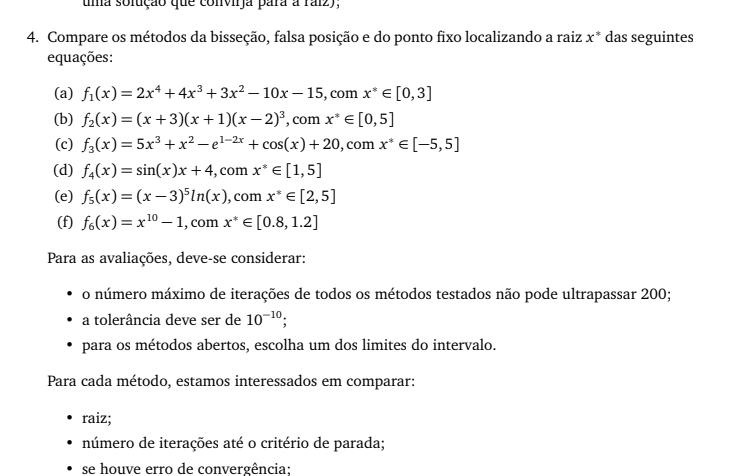

In [5]:
raiz1 = gradiente_descendente(f1, df1, 0, 3, 0.5, 0.0001, 200)
print(raiz1)
raiz2 = gradiente_descendente(f2, df2, 0, 5, 0.5, 0.00001, 200)
print(raiz2)
raiz3 = gradiente_descendente(f3, df3, -5, 5, 0.5, 0.00000000001, 200)
print(raiz3)
raiz4 = gradiente_descendente(f4, df4, 1, 5, 0.5, 0.01, 200)
print(raiz4)
raiz5 = gradiente_descendente(f5, df5, 2, 5, 0.5, 0.00001, 200)
print(raiz5)
raiz6 = gradiente_descendente(f6, df6, 0.8, 1.2, 0.1, 0.00001, 200)
print(raiz6)

[1.49288]
[2.0]
[]
[np.float64(4.32324)]
[3.0]
[1.0]


# ***RELATORIO:***

# 1. Funcionamento do Algoritmo:
O método transforma a busca de raízes de f(x) = 0 em um problema de minimização de erro usando a função objetiva quadrática: E(x) = 1/2*[f(x)]^2 Utiliza-se o erro quadrático por ser continuamente diferenciável. Aplicando a derivada de E(x), a regra de atualização é: x_{k+1} = x_k - alpha * f(x_k) * f'(x_k)

# **2- Implementação**
A capacidade de encontrar múltiplas raízes foi implementada via varredura por malha. Ou seja, teste de vários pontos de partida ao mesmo tempo para o algoritmo não deixar nenhuma raiz para trás. Cada ponto do intervalo serve de partida para a descida do gradiente.

# **3- Arranjo de testes:**

Critérios fixos: No máximo 200 interações e com uma tolerancia de convergência de 10^-10.

Varredura: Foi ajustado para 0.5, apenas para a função f6 que foi usado 0.1 (pois tinha um intervalo curto [0.8 , 1.2]).

Taxa de aprendizagem(alpha): Teve que ser reduzida progressivamente para conter os OverflowError causados por gradientes elevados.

# **4- Resultado e discussão**

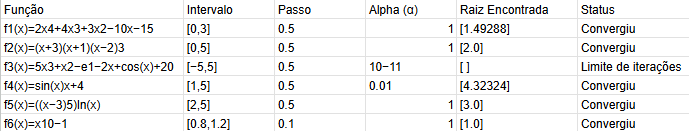